In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

df["text"] = df["headline"] + " " + df["body_text"]

print(df[["news_id", "label", "text"]].head())

   news_id label                                               text
0        1  Real  Global economy faces recession The Prime Minis...
1        2  Real  Earthquake hits Chittagong, panic spreads Gove...
2        3  Fake  Breakthrough in Bangladesh's tech industry Loc...
3        4  Fake  Dengue situation worsens in the country The Pr...
4        5  Real  New virus outbreak sparks fear Government sour...


In [10]:
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_text"] = df["text"].apply(preprocess_text)

print(df[["label", "cleaned_text"]].head())

  label                                       cleaned_text
0  Real  global economy faces recession the prime minis...
1  Real  earthquake hits chittagong panic spreads gover...
2  Fake  breakthrough in bangladesh s tech industry loc...
3  Fake  dengue situation worsens in the country the pr...
4  Real  new virus outbreak sparks fear government sour...


In [11]:
fake_text = df[df["label"].str.lower() == "fake"]["cleaned_text"]
real_text = df[df["label"].str.lower() == "real"]["cleaned_text"]

count_vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000
)

fake_matrix = count_vectorizer.fit_transform(fake_text)
fake_words = count_vectorizer.get_feature_names_out()

fake_frequency = np.asarray(fake_matrix.sum(axis=0)).flatten()

real_matrix = count_vectorizer.fit_transform(real_text)
real_words = count_vectorizer.get_feature_names_out()

real_frequency = np.asarray(real_matrix.sum(axis=0)).flatten()

fake_frequency_df = pd.DataFrame({
    "word": fake_words,
    "frequency": fake_frequency
}).sort_values("frequency", ascending=False)

real_frequency_df = pd.DataFrame({
    "word": real_words,
    "frequency": real_frequency
}).sort_values("frequency", ascending=False)

print("Top Fake News Words:")
print(fake_frequency_df.head(20))

print("\nTop Real News Words:")
print(real_frequency_df.head(20))

Top Fake News Words:
             word  frequency
58            new        309
10     bangladesh        239
33        experts        233
37     government        206
16       captures        135
5       astronaut        135
65          photo        135
55           moon        135
11    bangladeshi        135
7    authenticity        129
72        remains        129
88    uncertainty        129
42       incident        129
44       industry        128
14   breakthrough        128
86           tech        128
13        believe        123
1     advancement        123
77    significant        123
87  technological        123

Top Real News Words:
              word  frequency
58             new        334
10      bangladesh        239
33         experts        215
37      government        184
24             cup        141
94            wins        141
96           world        141
52           media        130
79          social        130
60            noon        130
59            news

In [12]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

fake_tfidf = tfidf_vectorizer.fit_transform(fake_text)
fake_tfidf_words = tfidf_vectorizer.get_feature_names_out()

fake_tfidf_scores = np.asarray(fake_tfidf.mean(axis=0)).flatten()

real_tfidf = tfidf_vectorizer.fit_transform(real_text)
real_tfidf_words = tfidf_vectorizer.get_feature_names_out()

real_tfidf_scores = np.asarray(real_tfidf.mean(axis=0)).flatten()

fake_tfidf_df = pd.DataFrame({
    "word": fake_tfidf_words,
    "tfidf_score": fake_tfidf_scores
}).sort_values("tfidf_score", ascending=False)

real_tfidf_df = pd.DataFrame({
    "word": real_tfidf_words,
    "tfidf_score": real_tfidf_scores
}).sort_values("tfidf_score", ascending=False)

print("Top Fake News TF-IDF Words:")
print(fake_tfidf_df.head(20))

print("\nTop Real News TF-IDF Words:")
print(real_tfidf_df.head(20))

Top Fake News TF-IDF Words:
             word  tfidf_score
58            new     0.061140
10     bangladesh     0.055282
33        experts     0.053934
37     government     0.047491
7    authenticity     0.039695
42       incident     0.039695
72        remains     0.039695
88    uncertainty     0.039695
86           tech     0.037469
14   breakthrough     0.037469
44       industry     0.037469
77    significant     0.036633
13        believe     0.036633
1     advancement     0.036633
87  technological     0.036633
16       captures     0.036503
5       astronaut     0.036503
11    bangladeshi     0.036503
55           moon     0.036503
65          photo     0.036503

Top Real News TF-IDF Words:
              word  tfidf_score
58             new     0.065115
10      bangladesh     0.055558
33         experts     0.050860
37      government     0.043870
24             cup     0.040450
94            wins     0.040450
96           world     0.040450
32           event     0.038043
21  

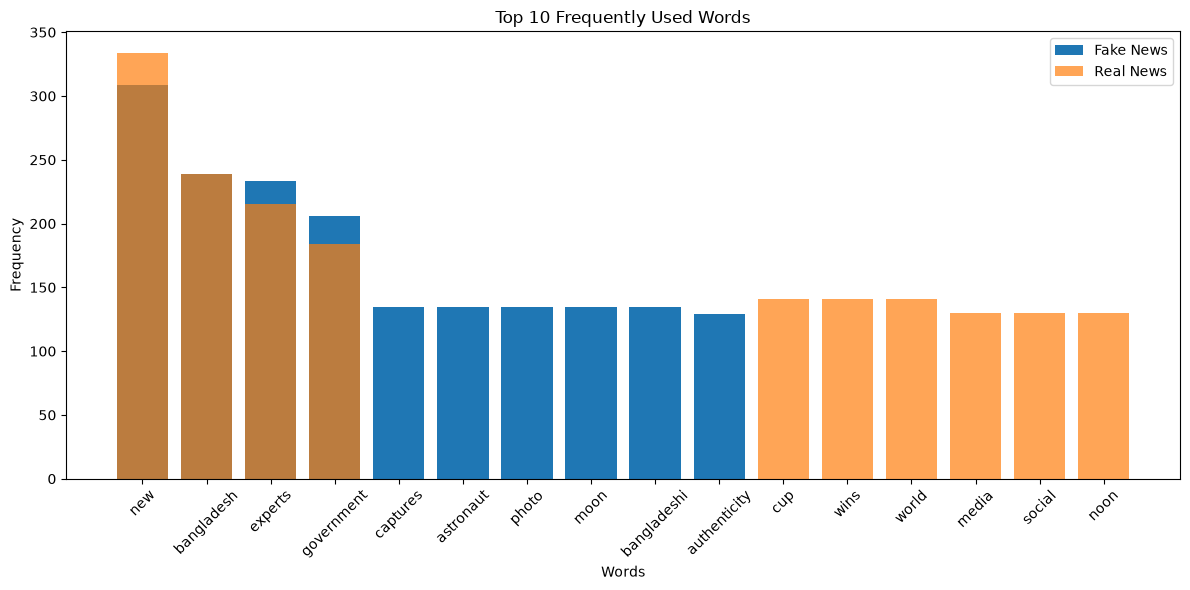

In [13]:
plt.figure(figsize=(12, 6))

plt.bar(
    fake_frequency_df.head(10)["word"],
    fake_frequency_df.head(10)["frequency"],
    label="Fake News"
)

plt.bar(
    real_frequency_df.head(10)["word"],
    real_frequency_df.head(10)["frequency"],
    label="Real News",
    alpha=0.7
)

plt.title("Top 10 Frequently Used Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

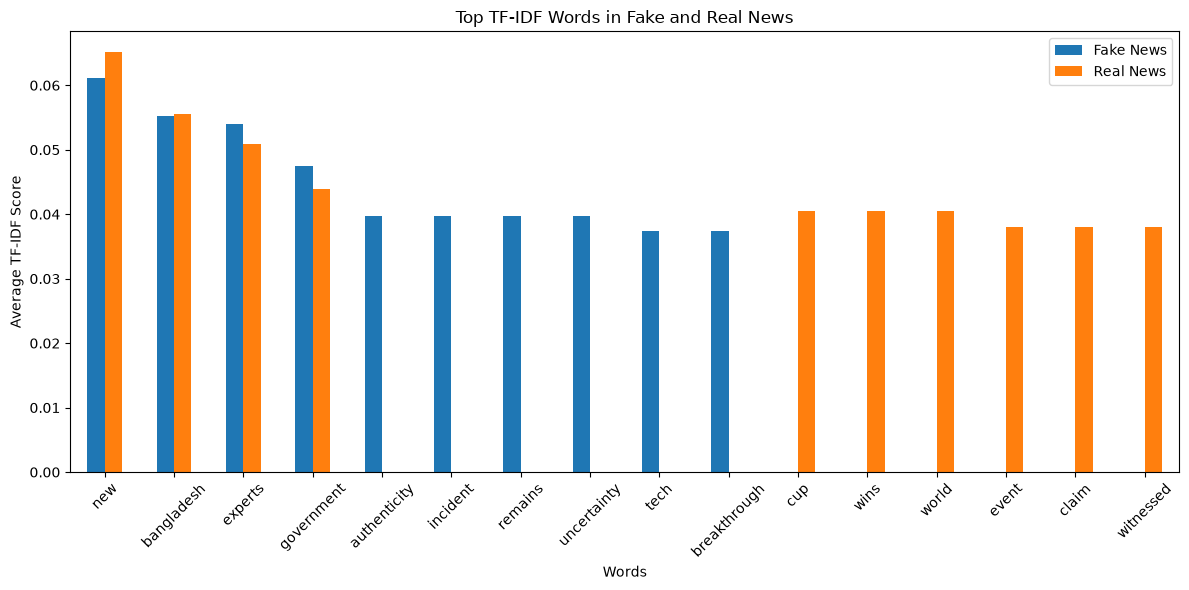

In [14]:
fake_top = fake_tfidf_df.head(10).set_index("word")
real_top = real_tfidf_df.head(10).set_index("word")

tfidf_comparison = pd.concat(
    [
        fake_top["tfidf_score"].rename("Fake News"),
        real_top["tfidf_score"].rename("Real News")
    ],
    axis=1
).fillna(0)

tfidf_comparison.plot(kind="bar", figsize=(12, 6))

plt.title("Top TF-IDF Words in Fake and Real News")
plt.xlabel("Words")
plt.ylabel("Average TF-IDF Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
frequency_statistics = pd.DataFrame({
    "Fake News": [
        fake_frequency_df["frequency"].mean(),
        fake_frequency_df["frequency"].std(),
        len(fake_frequency_df)
    ],
    "Real News": [
        real_frequency_df["frequency"].mean(),
        real_frequency_df["frequency"].std(),
        len(real_frequency_df)
    ]
}, index=["Mean Frequency", "Standard Deviation", "Vocabulary Size"])

print(frequency_statistics.round(3))

                    Fake News  Real News
Mean Frequency        116.929    115.296
Standard Deviation     30.183     31.203
Vocabulary Size        98.000     98.000


In [16]:
df.to_csv("T36_preprocessed_news.csv", index=False)

fake_frequency_df.to_csv("T37_fake_word_frequency.csv", index=False)
real_frequency_df.to_csv("T37_real_word_frequency.csv", index=False)

fake_tfidf_df.to_csv("T37_fake_tfidf.csv", index=False)
real_tfidf_df.to_csv("T37_real_tfidf.csv", index=False)

frequency_statistics.to_csv("T37_frequency_statistics.csv")